# PSL Match Winner Predictor (version 2: corrected and explained)

**Goal:** given two PSL teams, the venue and the toss, predict who wins the match.

### The big picture (the whole project in 9 steps)
| Step | What we do | Why |
|---|---|---|
| 1 | Read the 357 **JSON** files (one per match) | The raw data comes as JSON, which computers read well but is hard to analyse |
| 2 | Put one row per match into a **table (DataFrame)** and save it as **CSV** | Tables and CSV are what pandas and machine learning understand |
| 3 | **Clean** it (remove matches with no result, fix a venue name) | Garbage in, garbage out |
| 4 | **Look** at the data (does the toss matter?) | Understand before modelling |
| 5 | Build **features**: numbers that describe each team *before* the match (form, win rate, Elo rating...) | A model needs numbers to learn from |
| 6 | Test models with **walk-forward evaluation** (train on the past, test on the next season) | This copies real life: you never know the future |
| 7 | Compare with **baselines** and test if the difference is real | A model is only useful if it beats simple guessing |
| 8 | **Save** the best model | So we can use it later |
| 9 | Write a `predict_match()` function | So the project can actually *predict* |



## Step 0: Setup
**What's happening:** we import the tools (pandas for tables, numpy for maths, matplotlib/seaborn for charts) and tell the notebook where the data lives.
In Google Colab it mounts your Drive and unzips `psl_male_json.zip`. On a normal computer set the folder path in `PSL_JSON_DIR`.

In [1]:
import os, glob, json, zipfile, copy, warnings
from collections import defaultdict, deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

try:                                              # running in Google Colab
    from google.colab import drive
    drive.mount("/content/drive")
    ZIP_PATH = "/content/drive/MyDrive/Datasets/psl_male_json.zip"
    JSON_DIR = "/content/psl_json"
    OUT_DIR  = "/content/drive/MyDrive"
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(JSON_DIR)
except ImportError:                               # running on a normal computer
    JSON_DIR = os.environ.get("PSL_JSON_DIR", "psl_json")
    OUT_DIR  = os.environ.get("PSL_OUT_DIR", ".")

print(len(glob.glob(JSON_DIR + "/*.json")), "JSON files found")

Mounted at /content/drive
357 JSON files found


## Step 1: Read the JSON files and make one table
**What's happening:**
- Each `.json` file is **one cricket match**, stored like a nested dictionary: `info` (teams, venue, toss, result) and `innings` (every ball bowled).
- We only need the match summary, so for every file we pick out: date, season, venue, the two teams, toss winner, toss decision, who batted first and who won.
- All matches go into one **pandas DataFrame** (a table: one row = one match). Then we **save it as CSV**, a plain spreadsheet-like file.
- **New:** if a match is a *tie* it was decided by a super over; the JSON stores that winner in `outcome.eliminator`. We keep those matches instead of throwing them away.

In [2]:
rows = []
for f in glob.glob(JSON_DIR + "/*.json"):
    d = json.load(open(f))
    info = d["info"]
    toss = info.get("toss", {})
    out  = info.get("outcome", {})
    rows.append(dict(
        match_id      = int(os.path.basename(f)[:-5]),
        date          = pd.to_datetime(info["dates"][0]),
        season        = str(info["season"]),
        venue         = info.get("venue"),
        team1         = info["teams"][0],
        team2         = info["teams"][1],
        toss_winner   = toss.get("winner"),
        toss_decision = toss.get("decision"),
        bat_first     = d["innings"][0]["team"] if d["innings"] else None,
        winner        = out.get("winner") or out.get("eliminator"),   # super-over winner for ties
        result        = out.get("result", "normal")))

raw = pd.DataFrame(rows).sort_values(["date", "match_id"]).reset_index(drop=True)
raw.to_csv(os.path.join(OUT_DIR, "psl_matches_raw.csv"), index=False)   # JSON -> CSV
print(raw.shape)
raw.head()

(357, 11)


,match_id,date,season,venue,team1,team2,toss_winner,toss_decision,bat_first,winner,result
0,959175,2016-02-04,2015/16,Dubai International Cricket Stadium,Islamabad United,Quetta Gladiators,Quetta Gladiators,field,Islamabad United,Quetta Gladiators,normal
1,959177,2016-02-05,2015/16,Dubai International Cricket Stadium,Lahore Qalandars,Karachi Kings,Karachi Kings,field,Lahore Qalandars,Karachi Kings,normal
2,959179,2016-02-05,2015/16,Dubai International Cricket Stadium,Peshawar Zalmi,Islamabad United,Peshawar Zalmi,bat,Peshawar Zalmi,Peshawar Zalmi,normal
3,959181,2016-02-06,2015/16,Dubai International Cricket Stadium,Karachi Kings,Quetta Gladiators,Quetta Gladiators,field,Karachi Kings,Quetta Gladiators,normal
4,959183,2016-02-06,2015/16,Dubai International Cricket Stadium,Lahore Qalandars,Peshawar Zalmi,Peshawar Zalmi,field,Lahore Qalandars,Peshawar Zalmi,normal


## Step 2: Clean the data
**What's happening:**
1. Matches with **no result** (rain, abandoned) have no winner, so there is nothing to predict. We drop them.
2. The same stadium has two names ("National Bank Cricket Arena, Karachi" and "National Stadium, Karachi"). We make them one.
3. **Shuffle team order.** In the JSON, `team1` is just whichever team was listed first. If that order is not random, a model can accidentally learn "the first-listed team tends to lose". We flip a fair coin for every match to decide which team is called `team1`.
4. **Target:** `team1_won` = 1 if team1 won, else 0. This is what we try to predict.

In [3]:
print("Result types:", raw.result.value_counts().to_dict())

df = raw.dropna(subset=["winner"]).reset_index(drop=True)
df["venue"] = df["venue"].replace({"National Bank Cricket Arena, Karachi": "National Stadium, Karachi"})

rng  = np.random.default_rng(RANDOM_STATE)
swap = rng.random(len(df)) < 0.5                       # random 50% of matches
df.loc[swap, ["team1", "team2"]] = df.loc[swap, ["team2", "team1"]].to_numpy()

df["team1_won"] = (df["winner"] == df["team1"]).astype(int)   # TARGET
print(df.shape, "matches with a winner")
print("team1 win rate (should be close to 0.5):", round(df.team1_won.mean(), 3))
print(df.groupby("season").date.agg(["min", "max", "count"]).sort_values("min"))

Result types: {'normal': 350, 'tie': 4, 'no result': 3}
(354, 12) matches with a winner
team1 win rate (should be close to 0.5): 0.494
               min        max  count
season                              
2015/16 2016-02-04 2016-02-23     23
2016/17 2017-02-09 2017-03-05     23
2017/18 2018-02-22 2018-03-25     33
2018/19 2019-02-14 2019-03-17     34
2019/20 2020-02-20 2020-03-15     27
2020/21 2020-11-14 2021-03-03     18
2021    2021-06-09 2021-06-24     20
2021/22 2022-01-27 2022-02-27     34
2022/23 2023-02-13 2023-03-18     34
2023/24 2024-02-17 2024-03-18     32
2025    2025-04-11 2025-05-25     33
2026    2026-03-26 2026-05-03     43


## Step 3: A first look. Does the toss matter?
**What's happening:** before building any model we check simple facts.
- How often does the **toss winner** win the match?
- How often does the **chasing team** (batting second) win? This is our first **baseline**: the easiest rule to beat.
- A **p-value** tells us how likely such a result would be *by pure luck* if the toss did nothing. Small p-value (below 0.05) means "probably not luck".

Toss winner won 208 of 354 = 0.588   (p-value vs 50% = 0.0012)
Chasing team won: 0.562   <- baseline to beat
{'field': 267, 'bat': 87}


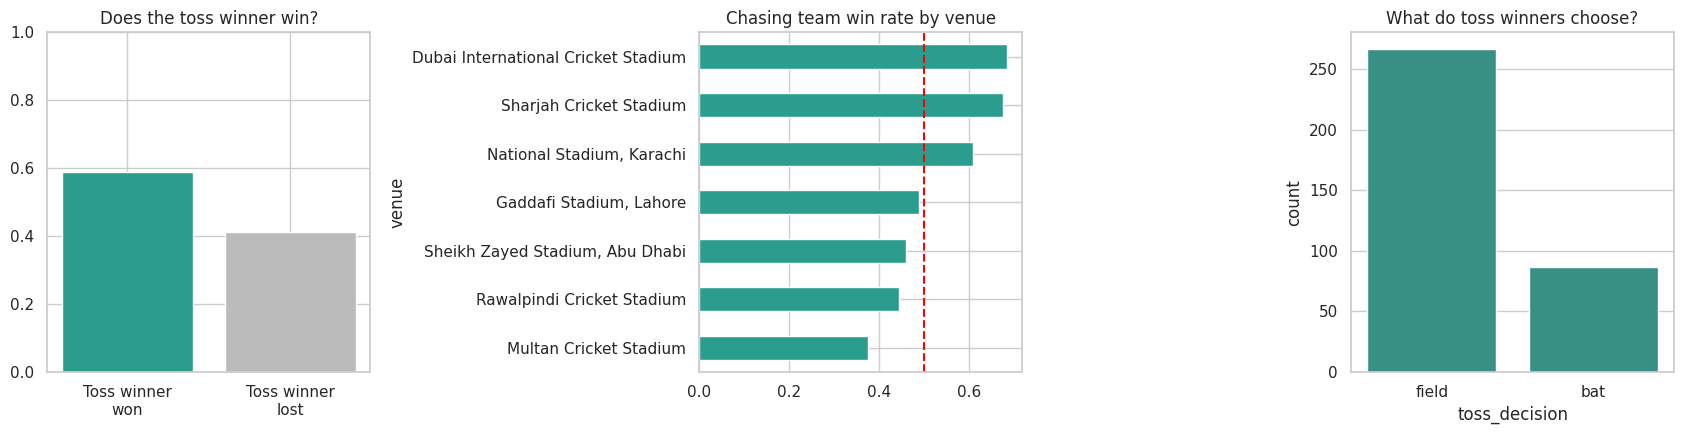

In [4]:
from scipy.stats import binomtest
toss_win = int((df.toss_winner == df.winner).sum())
print(f"Toss winner won {toss_win} of {len(df)} = {toss_win/len(df):.3f}   (p-value vs 50% = {binomtest(toss_win, len(df), 0.5).pvalue:.4f})")
print(f"Chasing team won: {(df.bat_first != df.winner).mean():.3f}   <- baseline to beat")
print(df.toss_decision.value_counts().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].bar(["Toss winner\nwon", "Toss winner\nlost"], [toss_win/len(df), 1-toss_win/len(df)], color=["#2a9d8f", "#bbbbbb"])
ax[0].set_ylim(0, 1); ax[0].set_title("Does the toss winner win?")
chase = (df.bat_first != df.winner).groupby(df.venue).mean().sort_values()
chase.plot.barh(ax=ax[1], color="#2a9d8f"); ax[1].axvline(0.5, color="red", ls="--"); ax[1].set_title("Chasing team win rate by venue")
sns.countplot(x="toss_decision", data=df, ax=ax[2], color="#2a9d8f"); ax[2].set_title("What do toss winners choose?")
plt.tight_layout(); plt.show()

## Step 4: Build features (numbers that describe the teams *before* the match)
**What's happening:** a model cannot read "Lahore Qalandars". It needs numbers. So we go through the matches **in date order** and, for each match, write down what we knew **before it started**:

| Feature | Meaning |
|---|---|
| `form_t1`, `form_t2` | win rate in the team's last 5 matches |
| `overall_t1`, `overall_t2` | win rate over all earlier matches |
| `h2h_t1` | how team1 did against this exact opponent before |
| `venue_t1`, `venue_t2` | how each team did at this venue before |
| `venue_chase_rate` | how often the chasing team wins at this venue |
| `toss_won_t1`, `toss_chose_bat`, `t1_bats_first` | toss information |
| `t1_home`, `t2_home` | is the venue in the team's home city? (**bug fixed**) |
| `elo_t1`, `elo_t2`, `elo_diff`, `elo_prob_t1` | **NEW: Elo rating.** Every team starts at 1500. Win and your rating goes up, lose and it goes down. Beating a strong team gives more points than beating a weak one. Between seasons ratings are pulled 25% back to 1500 because squads change. |
| `*_diff` | team1's number minus team2's number |

**The golden rule, no leakage:** we compute the features first and only *then* add the match result to the history. If we updated first, the model would "see" the answer.

Win rates are **smoothed** (`(wins + 1) / (played + 2)`) so a team with 1 match doesn't get an extreme 0% or 100%.

We put everything inside a `TeamState` object (a notebook-sized "memory"). This also lets us reuse it later for predicting future matches.

In [5]:
HOME = {"Lahore Qalandars": "Lahore", "Karachi Kings": "Karachi", "Multan Sultans": "Multan",
        "Islamabad United": "Rawalpindi", "Rawalpindiz": "Rawalpindi",
        "Peshawar Zalmi": "Peshawar", "Quetta Gladiators": "Quetta", "Hyderabad Kingsmen": "Hyderabad"}

def is_home(team, venue):
    city = HOME.get(team)                      # None if we don't know the team's home city
    return int(city is not None and city in venue)

# small named helpers (instead of lambdas) so the object can be copied safely
def _pair():  return [0, 0]
def _last5(): return deque(maxlen=5)
def _elo():   return 1500.0

def smooth_rate(wins_played, prior=0.5, k=2):
    w, p = wins_played
    return (w + prior * k) / (p + k)

class TeamState:
    K = 20                                     # how fast Elo moves after each match
    def __init__(self):
        self.last5   = defaultdict(_last5)     # recent results per team
        self.overall = defaultdict(_pair)      # [wins, played] per team
        self.h2h     = defaultdict(_pair)      # [wins, played] for (team, opponent)
        self.tv      = defaultdict(_pair)      # [wins, played] per (team, venue)
        self.chase_v = defaultdict(_pair)      # [chasing wins, played] per venue
        self.elo     = defaultdict(_elo)

    def new_season(self):
        for t in list(self.elo):
            self.elo[t] = 0.75 * self.elo[t] + 0.25 * 1500

    def features(self, t1, t2, venue, toss_winner, toss_decision, bat_first):
        e1, e2 = self.elo[t1], self.elo[t2]
        f = dict(
            form_t1    = np.mean(self.last5[t1]) if self.last5[t1] else 0.5,
            form_t2    = np.mean(self.last5[t2]) if self.last5[t2] else 0.5,
            overall_t1 = smooth_rate(self.overall[t1]),
            overall_t2 = smooth_rate(self.overall[t2]),
            h2h_t1     = smooth_rate(self.h2h[(t1, t2)]),
            venue_t1   = smooth_rate(self.tv[(t1, venue)]),
            venue_t2   = smooth_rate(self.tv[(t2, venue)]),
            venue_chase_rate = smooth_rate(self.chase_v[venue]),
            toss_won_t1    = int(toss_winner == t1),
            toss_chose_bat = int(toss_decision == "bat"),
            t1_bats_first  = int(bat_first == t1),
            t1_home = is_home(t1, venue),
            t2_home = is_home(t2, venue),
            elo_t1 = e1, elo_t2 = e2,
            elo_prob_t1 = 1 / (1 + 10 ** ((e2 - e1) / 400)))
        f["form_diff"]    = f["form_t1"] - f["form_t2"]
        f["overall_diff"] = f["overall_t1"] - f["overall_t2"]
        f["venue_diff"]   = f["venue_t1"] - f["venue_t2"]
        f["elo_diff"]     = e1 - e2
        return f

    def update(self, t1, t2, venue, winner, bat_first):      # call AFTER features()
        loser = t2 if winner == t1 else t1
        self.last5[winner].append(1); self.last5[loser].append(0)
        self.overall[winner][0] += 1; self.overall[winner][1] += 1; self.overall[loser][1] += 1
        self.h2h[(winner, loser)][0] += 1; self.h2h[(winner, loser)][1] += 1; self.h2h[(loser, winner)][1] += 1
        self.tv[(winner, venue)][0] += 1; self.tv[(winner, venue)][1] += 1; self.tv[(loser, venue)][1] += 1
        self.chase_v[venue][1] += 1
        if bat_first != winner:
            self.chase_v[venue][0] += 1
        expected = 1 / (1 + 10 ** ((self.elo[loser] - self.elo[winner]) / 400))
        change = self.K * (1 - expected)
        self.elo[winner] += change
        self.elo[loser]  -= change

state, feats, prev_season = TeamState(), [], None
for r in df.itertuples():
    if prev_season is not None and r.season != prev_season:
        state.new_season()
    prev_season = r.season
    feats.append(state.features(r.team1, r.team2, r.venue, r.toss_winner, r.toss_decision, r.bat_first))
    state.update(r.team1, r.team2, r.venue, r.winner, r.bat_first)      # history updated AFTER

data = pd.concat([df, pd.DataFrame(feats)], axis=1)
final_state = state                                   # memory after the last match (used for predictions)
data.to_csv(os.path.join(OUT_DIR, "psl_features.csv"), index=False)     # table -> CSV again
print(data.shape)
data.head()

(354, 32)


,match_id,date,season,venue,team1,team2,toss_winner,toss_decision,bat_first,winner,...,t1_bats_first,t1_home,t2_home,elo_t1,elo_t2,elo_prob_t1,form_diff,overall_diff,venue_diff,elo_diff
0,959175,2016-02-04,2015/16,Dubai International Cricket Stadium,Islamabad United,Quetta Gladiators,Quetta Gladiators,field,Islamabad United,Quetta Gladiators,...,1,0,0,1500.000000,1500.0,0.500000,0.0,0.000000,0.000000,0.000000
1,959177,2016-02-05,2015/16,Dubai International Cricket Stadium,Karachi Kings,Lahore Qalandars,Karachi Kings,field,Lahore Qalandars,Karachi Kings,...,0,0,0,1500.000000,1500.0,0.500000,0.0,0.000000,0.000000,0.000000
2,959179,2016-02-05,2015/16,Dubai International Cricket Stadium,Peshawar Zalmi,Islamabad United,Peshawar Zalmi,bat,Peshawar Zalmi,Peshawar Zalmi,...,1,0,0,1500.000000,1490.0,0.514387,0.5,0.166667,0.166667,10.000000
3,959181,2016-02-06,2015/16,Dubai International Cricket Stadium,Karachi Kings,Quetta Gladiators,Quetta Gladiators,field,Karachi Kings,Quetta Gladiators,...,1,0,0,1510.000000,1510.0,0.500000,0.0,0.000000,0.000000,0.000000
4,959183,2016-02-06,2015/16,Dubai International Cricket Stadium,Peshawar Zalmi,Lahore Qalandars,Peshawar Zalmi,field,Lahore Qalandars,Peshawar Zalmi,...,0,0,0,1509.712256,1490.0,0.528338,1.0,0.333333,0.333333,19.712256


**Sanity check:** the Elo ratings after the last match should look believable (strong recent teams on top). If a team that always loses is at the top, something is wrong.

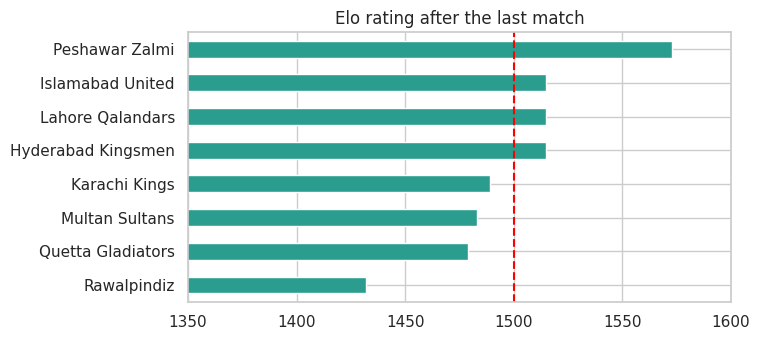

In [6]:
elo_now = pd.Series(dict(final_state.elo)).sort_values(ascending=False).round(0)
elo_now.plot.barh(figsize=(7, 3.5), color="#2a9d8f", title="Elo rating after the last match"); plt.xlim(1350, 1600); plt.axvline(1500, color="red", ls="--"); plt.gca().invert_yaxis(); plt.show()

## Step 5: Test the models with walk-forward evaluation
**What's happening, and why this is better than before:**

In real life you predict a match using only the **past**. So we imitate that:

```
Train on seasons 1-3  ->  test on season 4
Train on seasons 1-4  ->  test on season 5
Train on seasons 1-5  ->  test on season 6   ... and so on
```
Every match is predicted by a model that **never saw it or anything after it**. (Your first version sometimes trained on 2025 data to predict 2016, which is cheating.) We then pool all predictions and measure accuracy.

**Models we compare**
- **Logistic Regression:** draws a straight "line" between winners and losers. Simple and hard to overfit.
- **Logistic (Elo only):** the same, but using only the Elo difference. A very simple model.
- **Logistic (no toss):** can predict *before* the toss happens.
- **Logistic (toss + Elo):** only 2 features. *Exploratory:* we added it after seeing the first results, to test whether "fewer features" helps on tiny data.
- **Random Forest:** many decision trees voting.
- **SVM:** another "line drawer" with a margin.
- **Keras neural network:** small deep-learning model.

**Baselines** (dumb rules a model must beat to be useful): always pick the chasing team, the toss winner, the team with better recent form, the team with the higher Elo rating.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, log_loss

TARGET = "team1_won"
FEATURES = ["form_t1","form_t2","overall_t1","overall_t2","h2h_t1","venue_t1","venue_t2",
            "venue_chase_rate","toss_won_t1","toss_chose_bat","t1_bats_first","t1_home","t2_home",
            "form_diff","overall_diff","venue_diff","elo_t1","elo_t2","elo_diff","elo_prob_t1"]
TOSS_FEATURES = ["toss_won_t1", "toss_chose_bat", "t1_bats_first"]
NO_TOSS = [f for f in FEATURES if f not in TOSS_FEATURES]

def make_lr():  return Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(C=1, max_iter=1000))])
def make_rf():  return RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=8, random_state=RANDOM_STATE)
def make_svm(): return Pipeline([("sc", StandardScaler()), ("m", SVC(C=0.1, kernel="linear", probability=True, random_state=RANDOM_STATE))])

sk_models = {                      # name: (how to build it, which features it may use)
    "Logistic Regression":  (make_lr,  FEATURES),
    "Logistic (no toss)":   (make_lr,  NO_TOSS),
    "Logistic (Elo only)":  (make_lr,  ["elo_diff"]),
    "Logistic (toss + Elo)": (make_lr, ["toss_won_t1", "elo_diff"]),
    "Random Forest":       (make_rf,  FEATURES),
    "SVM":                  (make_svm, FEATURES),
}

try:
    import tensorflow as tf
    from tensorflow import keras
    HAS_TF = True
except ImportError:
    HAS_TF = False
    print("TensorFlow not installed: the Keras model will be skipped")

def keras_fit_predict(Xtr, ytr, Xte):
    keras.backend.clear_session(); tf.random.set_seed(RANDOM_STATE)
    sc = StandardScaler().fit(Xtr)
    nn = keras.Sequential([
        keras.layers.Input(shape=(Xtr.shape[1],)),
        keras.layers.Dense(16, activation="relu"), keras.layers.Dropout(0.3),
        keras.layers.Dense(8, activation="relu"),  keras.layers.Dense(1, activation="sigmoid")])
    nn.compile(optimizer="adam", loss="binary_crossentropy")
    nn.fit(sc.transform(Xtr), ytr, validation_split=0.2, epochs=100, batch_size=16, verbose=0,
           callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)])
    return nn(sc.transform(Xte).astype("float32"), training=False).numpy().ravel()

season_order = data.groupby("season")["date"].min().sort_values().index.tolist()
MIN_TRAIN_SEASONS = 3
print("Seasons in time order:", season_order)

names = list(sk_models) + (["Keras NN"] if HAS_TF else [])
proba = {n: pd.Series(np.nan, index=data.index) for n in names}

for k in range(MIN_TRAIN_SEASONS, len(season_order)):
    tr = data.season.isin(season_order[:k]).values          # all earlier seasons
    te = (data.season == season_order[k]).values            # the next season
    for name, (make, cols) in sk_models.items():
        m = make().fit(data.loc[tr, cols], data.loc[tr, TARGET])
        proba[name].loc[te] = m.predict_proba(data.loc[te, cols])[:, 1]
    if HAS_TF:
        proba["Keras NN"].loc[te] = keras_fit_predict(data.loc[tr, FEATURES], data.loc[tr, TARGET], data.loc[te, FEATURES])
    print(f"tested on {season_order[k]:8s} ({te.sum():2d} matches), trained on {tr.sum()} earlier matches")

evaluated = data.season.isin(season_order[MIN_TRAIN_SEASONS:]).values
D = data[evaluated]; y = D[TARGET].values
print("\nMatches predicted:", len(D))

Seasons in time order: ['2015/16', '2016/17', '2017/18', '2018/19', '2019/20', '2020/21', '2021', '2021/22', '2022/23', '2023/24', '2025', '2026']
tested on 2018/19  (34 matches), trained on 79 earlier matches
tested on 2019/20  (27 matches), trained on 113 earlier matches
tested on 2020/21  (18 matches), trained on 140 earlier matches
tested on 2021     (20 matches), trained on 158 earlier matches
tested on 2021/22  (34 matches), trained on 178 earlier matches
tested on 2022/23  (34 matches), trained on 212 earlier matches
tested on 2023/24  (32 matches), trained on 246 earlier matches
tested on 2025     (33 matches), trained on 278 earlier matches
tested on 2026     (43 matches), trained on 311 earlier matches

Matches predicted: 275


## Step 6: Results table
**What's happening:** we turn each model's probability into a pick (above 50% means "team1 wins") and measure:
- **accuracy:** share of matches predicted correctly
- **F1:** balance between catching team1 wins and not raising false alarms
- **AUC:** how well the probabilities *rank* winners above losers (0.5 = coin flip, 1.0 = perfect). It is less noisy than accuracy
- **log loss:** punishes confident wrong probabilities (lower is better; 0.693 = coin flip)

In [8]:
preds = {n: (proba[n][evaluated].values > 0.5).astype(int) for n in names}
base = {
    "Baseline: chasing team":  (D.bat_first != D.team1).astype(int).values,
    "Baseline: toss winner":   D.toss_won_t1.values,
    "Baseline: better form":   (D.form_diff > 0).astype(int).values,
    "Baseline: higher Elo":    (D.elo_diff > 0).astype(int).values,
}
preds.update(base)

rows = []
for n, p in preds.items():
    pr = proba[n][evaluated].values if n in proba else None
    rows.append(dict(model=n, accuracy=accuracy_score(y, p), f1=f1_score(y, p),
                     auc=roc_auc_score(y, pr) if pr is not None else np.nan,
                     log_loss=log_loss(y, pr) if pr is not None else np.nan))
results = pd.DataFrame(rows).set_index("model").round(3)
results.to_csv(os.path.join(OUT_DIR, "walkforward_results.csv"))
results

,accuracy,f1,auc,log_loss
model,,,,
Logistic Regression,0.535,0.488,0.507,0.770
Logistic (no toss),0.495,0.463,0.469,0.769
Logistic (Elo only),0.487,0.558,0.485,0.698
Logistic (toss + Elo),0.596,0.561,0.588,0.682
Random Forest,0.476,0.455,0.510,0.707
SVM,0.516,0.474,0.518,0.707
Keras NN,0.495,0.491,0.460,0.762
Baseline: chasing team,0.545,0.532,NaN,NaN
Baseline: toss winner,0.596,0.561,NaN,NaN


**Accuracy in each test season.** One season is only 20-40 matches, so a single season can swing a lot. This is why one small test set can mislead (your first notebook used only 76 matches).

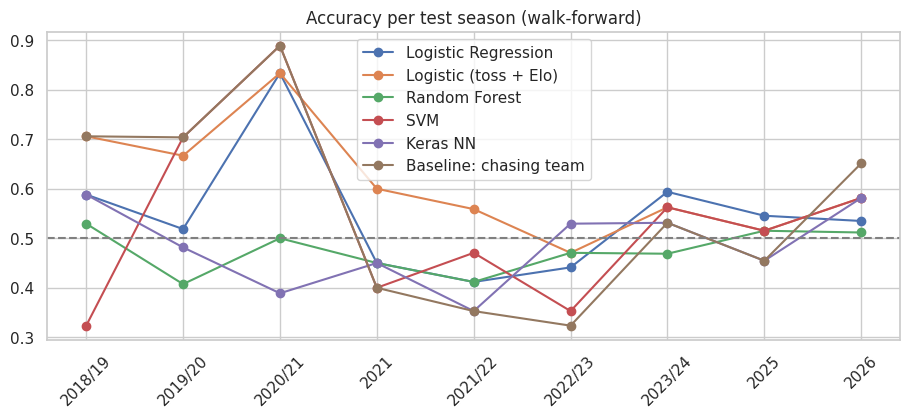

Std of accuracy across seasons:
 Logistic Regression       0.125
Logistic (toss + Elo)     0.110
Random Forest             0.044
SVM                       0.179
Keras NN                  0.081
Baseline: chasing team    0.192
dtype: float64


In [9]:
acc_season = pd.DataFrame({n: pd.Series(preds[n] == y).groupby(D.season.values).mean() for n in
                           ["Logistic Regression", "Logistic (toss + Elo)", "Random Forest", "SVM"] + (["Keras NN"] if HAS_TF else []) + ["Baseline: chasing team"]})
acc_season = acc_season.loc[[s for s in season_order if s in acc_season.index]]
acc_season.plot(marker="o", figsize=(11, 4), title="Accuracy per test season (walk-forward)")
plt.axhline(0.5, color="grey", ls="--"); plt.xticks(rotation=45); plt.show()
print("Std of accuracy across seasons:\n", acc_season.std().round(3))

## Step 7: Is a model *really* better than the baseline?
**What's happening:** a model with 58% vs a baseline with 56% could easily be luck. **McNemar's test** looks only at the matches where the model and the baseline *disagree* and asks: is the model right more often than chance would explain? Small p-value (< 0.05) = a real difference. We also print a 95% range for each accuracy, because with a few hundred matches the uncertainty is about +/- 6 points.

In [10]:
def mcnemar_p(correct_a, correct_b):
    b = int((correct_a & ~correct_b).sum()); c = int((~correct_a & correct_b).sum())
    return 1.0 if b + c == 0 else binomtest(b, b + c, 0.5).pvalue

def acc_interval(correct, n_boot=2000, seed=0):
    r = np.random.default_rng(seed)
    boots = [correct[r.integers(0, len(correct), len(correct))].mean() for _ in range(n_boot)]
    return np.percentile(boots, [2.5, 97.5])

ref = preds["Baseline: chasing team"] == y
print(f"Reference baseline (always chasing team): {ref.mean():.3f}\n")
for n in names + [b for b in base if b != "Baseline: chasing team"]:
    c = preds[n] == y
    lo, hi = acc_interval(c)
    print(f"{n:22s} acc={c.mean():.3f}  95% range [{lo:.3f}, {hi:.3f}]   McNemar p vs baseline = {mcnemar_p(c, ref):.3f}")

Reference baseline (always chasing team): 0.545

Logistic Regression    acc=0.535  95% range [0.476, 0.593]   McNemar p vs baseline = 0.822
Logistic (no toss)     acc=0.495  95% range [0.433, 0.553]   McNemar p vs baseline = 0.282
Logistic (Elo only)    acc=0.487  95% range [0.425, 0.545]   McNemar p vs baseline = 0.214
Logistic (toss + Elo)  acc=0.596  95% range [0.542, 0.658]   McNemar p vs baseline = 0.125
Random Forest          acc=0.476  95% range [0.415, 0.538]   McNemar p vs baseline = 0.078
SVM                    acc=0.516  95% range [0.458, 0.575]   McNemar p vs baseline = 0.428
Keras NN               acc=0.495  95% range [0.433, 0.553]   McNemar p vs baseline = 0.219
Baseline: toss winner  acc=0.596  95% range [0.542, 0.658]   McNemar p vs baseline = 0.125
Baseline: better form  acc=0.545  95% range [0.491, 0.604]   McNemar p vs baseline = 1.000
Baseline: higher Elo   acc=0.524  95% range [0.465, 0.586]   McNemar p vs baseline = 0.675


## Step 8: ROC curves and calibration
**ROC curve:** the further a line bends toward the top-left corner, the better the model. The diagonal is a coin flip.
**Calibration:** when a model says "70% chance", does that team win about 70% of the time? Points near the diagonal mean the probabilities can be trusted.

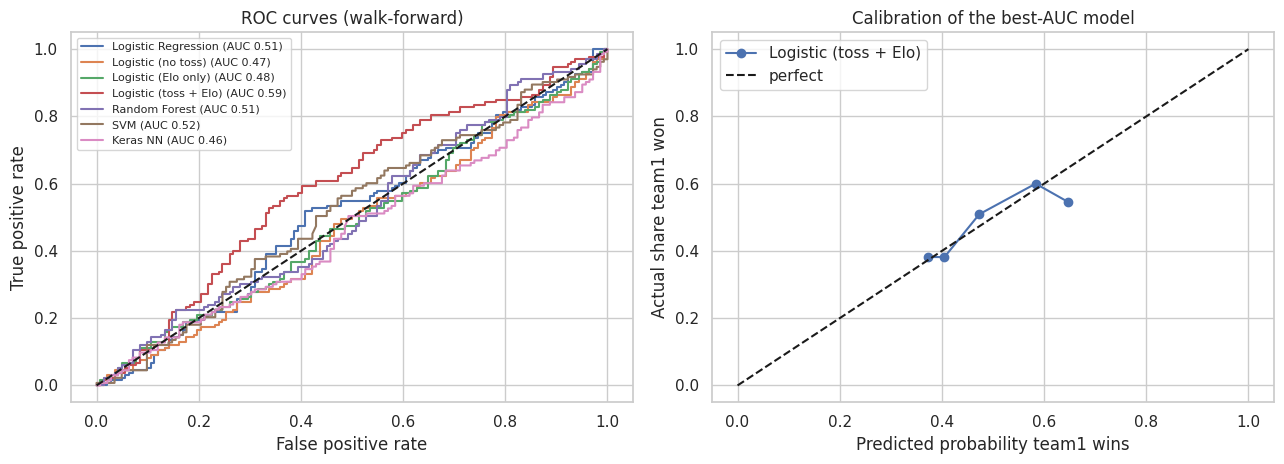

In [11]:
from sklearn.metrics import roc_curve
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for n in names:
    fpr, tpr, _ = roc_curve(y, proba[n][evaluated].values)
    ax[0].plot(fpr, tpr, label=f"{n} (AUC {results.loc[n, 'auc']:.2f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curves (walk-forward)"); ax[0].legend(fontsize=8)

best_auc = results.loc[names, "auc"].idxmax()
frac, mean_pred = calibration_curve(y, proba[best_auc][evaluated].values, n_bins=5, strategy="quantile")
ax[1].plot(mean_pred, frac, "o-", label=best_auc); ax[1].plot([0, 1], [0, 1], "k--", label="perfect")
ax[1].set_xlabel("Predicted probability team1 wins"); ax[1].set_ylabel("Actual share team1 won")
ax[1].set_title("Calibration of the best-AUC model"); ax[1].legend()
plt.tight_layout(); plt.show()

## Step 9: What does the model use? (feature importance)
**What's happening:** Logistic Regression gives each feature a **coefficient** (after scaling). A big positive number means "when this is high, team1 is more likely to win"; negative means the opposite. This tells us *what the model thinks matters*.

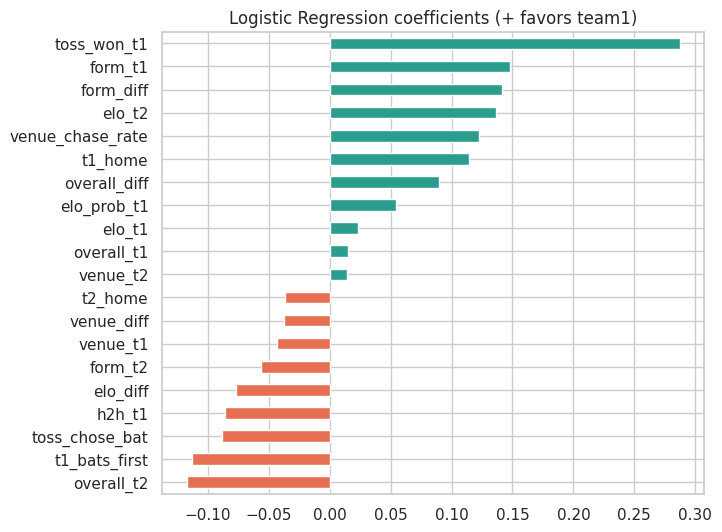

In [12]:
lr_all = make_lr().fit(data[FEATURES], data[TARGET])
coef = pd.Series(lr_all.named_steps["m"].coef_[0], index=FEATURES).sort_values()
coef.plot.barh(figsize=(7, 6), color=np.where(coef > 0, "#2a9d8f", "#e76f51"),
               title="Logistic Regression coefficients (+ favors team1)"); plt.show()

## Step 10: Save the best model
**What's happening:** we pick the best scikit-learn model by **AUC** (more stable than accuracy on small data), retrain it on **all** matches (more data = better), and save it with `joblib`. The saved file is a whole **pipeline** (scaler + model), so nobody has to remember to scale the inputs. (Version 1 saved the Random Forest, the worst model, by mistake.)

Remember: picking the winner out of several models is slightly optimistic, because we chose the one that happened to do best.

In [13]:
import joblib
sk_names = list(sk_models)
best_name = results.loc[sk_names, "auc"].idxmax()
make, best_cols = sk_models[best_name]
best_model = make().fit(data[best_cols], data[TARGET])
joblib.dump({"name": best_name, "features": best_cols, "model": best_model},
            os.path.join(OUT_DIR, "psl_best_model.pkl"))
print("Saved:", best_name, "| uses", len(best_cols), "features")

Saved: Logistic (toss + Elo) | uses 2 features


## Step 11: Predict a new match
**What's happening:** `predict_match()` builds the same features for the new match (using each team's history up to today), asks the saved model for a probability, and prints it.

Because team order is arbitrary, we ask the model **twice** (once with each team as "team1") and average. This removes any leftover bias from the order.
- `toss_decision` is `"bat"` or `"field"`.
- Use `new_season=True` when predicting the first match of a new season (applies the Elo reset).

In [14]:
def predict_match(team1, team2, venue, toss_winner, toss_decision, new_season=False):
    known = set(final_state.elo)
    for t in (team1, team2):
        if t not in known:
            raise ValueError(f"Unknown team '{t}'. Known teams: {sorted(known)}")
    if toss_winner not in (team1, team2):
        raise ValueError("toss_winner must be team1 or team2")
    if toss_decision not in ("bat", "field"):
        raise ValueError("toss_decision must be 'bat' or 'field'")
    st = copy.deepcopy(final_state)
    if new_season:
        st.new_season()

    def p_first_wins(a, b):
        bat_first = toss_winner if toss_decision == "bat" else (b if toss_winner == a else a)
        f = st.features(a, b, venue, toss_winner, toss_decision, bat_first)
        return best_model.predict_proba(pd.DataFrame([f])[best_cols])[0, 1]

    p1 = (p_first_wins(team1, team2) + 1 - p_first_wins(team2, team1)) / 2
    print(f"{team1}: {p1:.0%}   vs   {team2}: {1 - p1:.0%}   -> predicted winner: {team1 if p1 >= 0.5 else team2}")
    return p1

_ = predict_match("Lahore Qalandars", "Multan Sultans", "Gaddafi Stadium, Lahore", "Lahore Qalandars", "field")
_ = predict_match("Karachi Kings", "Islamabad United", "National Stadium, Karachi", "Islamabad United", "bat")
_ = predict_match("Peshawar Zalmi", "Quetta Gladiators", "Rawalpindi Cricket Stadium", "Quetta Gladiators", "field")

Lahore Qalandars: 61%   vs   Multan Sultans: 39%   -> predicted winner: Lahore Qalandars
Karachi Kings: 39%   vs   Islamabad United: 61%   -> predicted winner: Islamabad United
Peshawar Zalmi: 48%   vs   Quetta Gladiators: 52%   -> predicted winner: Quetta Gladiators


# Step 12: Player-level features (new section)

**Idea:** so far a team was just a *name* with a win/loss history. But a team is really **11 players**, and the players change from match to match. So we look at who is actually in the playing XI and ask: *how good are these 11 batters and bowlers, based on everything they did in earlier matches?*

**What's happening, in simple words**
1. For every match we open the JSON file again and read **every ball**: who faced it, who bowled it, runs scored, wickets.
2. We keep a running record for each player. **Batting:** runs, balls faced, times dismissed. **Bowling:** balls bowled, runs conceded, wickets.
3. Before each match we turn those records into numbers for each player:
   - **Batting strike rate** = runs per 100 balls
   - **Batting average** = runs per dismissal
   - **Bowling economy** = runs conceded per over (lower is better)
   - **Bowling wickets** = wickets per over
4. We combine the 11 players into one number per team. A player who usually faces more balls (an opener) counts more than a number 11. A bowler who bowls more overs counts more than a part-timer.
5. **No leakage:** a match is added to the player records only *after* its features are computed, exactly like Elo and form earlier.
6. **Small-sample protection:** a player with 10 balls of history would otherwise show a crazy strike rate (e.g. 300). So each player's numbers are **pulled toward the league average** until he has enough balls. A completely new player simply gets the league average.
7. We skip **super-over** innings (they are not normal cricket).

**Important:** the playing XI is announced at the toss. So these features, like the toss ones, are available only **after the toss**, not days before.

**Which of your cells to re-run:** nothing above needs to change. If your Colab session is still alive, you only run the new cells below, top to bottom. If Colab disconnected, use Runtime > Run all.

### 12.1 Read the ball-by-ball data and define the player "memory"
`read_match_players()` opens one match file and returns the two XIs plus what each player did in that match.
`PlayerState` is the running record of every player (like `TeamState`, but for people). We use the player's unique **registry id** instead of the name, so two different people with the same name are never mixed up.

In [15]:
BOWLER_WICKETS = {"bowled", "caught", "lbw", "stumped", "caught and bowled", "hit wicket"}   # wickets credited to the bowler
NOT_OUT_KINDS  = {"retired hurt", "retired not out"}                                           # not a real dismissal

def _pstat():
    return dict(matches=0, runs=0, balls_faced=0, dismissals=0, balls_bowled=0, runs_conceded=0, wickets=0)

def read_match_players(match_id):
    """Open one match file. Returns: (XI per team as ids, stats of every player in this match, name->id map)."""
    d = json.load(open(f"{JSON_DIR}/{match_id}.json"))
    info = d["info"]
    ids = info["registry"]["people"]
    pid = lambda name: ids.get(name, name)
    xi  = {team: [pid(p) for p in players] for team, players in info["players"].items()}
    box = defaultdict(_pstat)
    for inn in d["innings"]:
        if inn.get("super_over"):                      # ignore super overs
            continue
        for over in inn.get("overs", []):
            for ball in over["deliveries"]:
                bat, bowl = pid(ball["batter"]), pid(ball["bowler"])
                extras = ball.get("extras", {})
                wide, noball = extras.get("wides", 0), extras.get("noballs", 0)
                box[bat]["runs"] += ball["runs"]["batter"]
                if not wide:                           # a wide is not a ball faced
                    box[bat]["balls_faced"] += 1
                if not wide and not noball:            # only legal balls count for the bowler
                    box[bowl]["balls_bowled"] += 1
                box[bowl]["runs_conceded"] += ball["runs"]["batter"] + wide + noball
                for w in ball.get("wickets", []):
                    if w["kind"] in BOWLER_WICKETS:
                        box[bowl]["wickets"] += 1
                    if w["kind"] not in NOT_OUT_KINDS:
                        box[pid(w["player_out"])]["dismissals"] += 1
    return xi, box, ids

# how strongly we pull a player toward the league average (bigger = more cautious)
K_BAT_BALLS, K_BAT_DISM, K_BOWL_BALLS = 60, 3, 90
TYPICAL_BALLS_PER_PLAYER = 11          # about 120 balls shared by 11 players

class PlayerState:
    def __init__(self):
        self.p  = defaultdict(_pstat)
        self.lg = dict(runs=0, balls=0, dism=0, conceded=0, bowled=0, wickets=0)    # league totals so far

    # league averages (with sensible fallbacks before we have enough data)
    def lg_rpb(self):  return self.lg["runs"] / self.lg["balls"]        if self.lg["balls"]  >= 300 else 1.30
    def lg_avg(self):  return self.lg["runs"] / self.lg["dism"]         if self.lg["dism"]   >= 20  else 25.0
    def lg_econ(self): return self.lg["conceded"] / self.lg["bowled"]   if self.lg["bowled"] >= 300 else 1.30
    def lg_wpb(self):  return self.lg["wickets"] / self.lg["bowled"]    if self.lg["bowled"] >= 300 else 0.045

    def bat_rates(self, pid):
        s = self.p[pid]
        rpb = (s["runs"] + self.lg_rpb() * K_BAT_BALLS) / (s["balls_faced"] + K_BAT_BALLS)     # runs per ball
        avg = (s["runs"] + self.lg_avg() * K_BAT_DISM)  / (s["dismissals"] + K_BAT_DISM)       # runs per dismissal
        weight = (s["balls_faced"] + TYPICAL_BALLS_PER_PLAYER * 2) / (s["matches"] + 2)        # usual balls faced per match
        return rpb, avg, weight

    def bowl_rates(self, pid):
        s = self.p[pid]
        econ = (s["runs_conceded"] + self.lg_econ() * K_BOWL_BALLS) / (s["balls_bowled"] + K_BOWL_BALLS)   # runs per ball
        wpb  = (s["wickets"] + self.lg_wpb() * K_BOWL_BALLS) / (s["balls_bowled"] + K_BOWL_BALLS)           # wickets per ball
        weight = (s["balls_bowled"] + TYPICAL_BALLS_PER_PLAYER * 2) / (s["matches"] + 2)                    # usual balls bowled per match
        return econ, wpb, weight

    def team_numbers(self, xi):
        bat  = [self.bat_rates(p)  for p in xi]
        bowl = [self.bowl_rates(p) for p in xi]
        wb, wo = [b[2] for b in bat], [b[2] for b in bowl]
        return dict(
            bat_sr    = 100 * np.average([b[0] for b in bat],  weights=wb),    # strike rate
            bat_avg   =       np.average([b[1] for b in bat],  weights=wb),    # batting average
            bowl_econ =   6 * np.average([b[0] for b in bowl], weights=wo),    # runs per over (lower = better)
            bowl_wkts =   6 * np.average([b[1] for b in bowl], weights=wo))    # wickets per over

    def features(self, xi1, xi2):
        a, b = self.team_numbers(xi1), self.team_numbers(xi2)
        f = {f"pl_{k}_t1": v for k, v in a.items()}
        f.update({f"pl_{k}_t2": v for k, v in b.items()})
        f["pl_bat_sr_diff"]    = a["bat_sr"]    - b["bat_sr"]
        f["pl_bat_avg_diff"]   = a["bat_avg"]   - b["bat_avg"]
        f["pl_bowl_econ_diff"] = a["bowl_econ"] - b["bowl_econ"]      # negative = team1 bowlers are better
        f["pl_bowl_wkts_diff"] = a["bowl_wkts"] - b["bowl_wkts"]
        # "net run strength" = runs a team's batters score per over minus runs its bowlers give away per over
        net_a = a["bat_sr"] * 6 / 100 - a["bowl_econ"]
        net_b = b["bat_sr"] * 6 / 100 - b["bowl_econ"]
        f["pl_net_diff"] = net_a - net_b
        return f

    def update(self, xi_by_team, box):                 # call AFTER features()
        for team_xi in xi_by_team.values():
            for p in team_xi:
                self.p[p]["matches"] += 1
        for p, s in box.items():
            for k in ("runs", "balls_faced", "dismissals", "balls_bowled", "runs_conceded", "wickets"):
                self.p[p][k] += s[k]
            self.lg["runs"]     += s["runs"];          self.lg["balls"]   += s["balls_faced"]
            self.lg["dism"]     += s["dismissals"]
            self.lg["conceded"] += s["runs_conceded"]; self.lg["bowled"]  += s["balls_bowled"]
            self.lg["wickets"]  += s["wickets"]

print("player code ready")

player code ready


### 12.2 Add the player features to every match
**What's happening:** we walk through the matches in date order again. For each match: read the XIs, compute the team numbers from **earlier** matches only, store them, then add this match's balls to the player records.
This takes a few seconds because it reads all 354 files.

In [16]:
pstate = PlayerState()
player_rows, name_to_id, id_to_name, latest_xi = [], {}, {}, {}
for r in data.itertuples():
    xi, box, ids = read_match_players(r.match_id)
    for name, pid_ in ids.items():
        name_to_id[name] = pid_; id_to_name[pid_] = name
    player_rows.append(pstate.features(xi[r.team1], xi[r.team2]))     # features first ...
    pstate.update(xi, box)                                             # ... history updated AFTER
    for team, players in xi.items():
        latest_xi[team] = players                                      # remember the most recent XI of each team

player_df = pd.DataFrame(player_rows, index=data.index)
for c in player_df.columns:
    data[c] = player_df[c]
PLAYER_FEATURES = ["pl_bat_sr_diff", "pl_bat_avg_diff", "pl_bowl_econ_diff", "pl_bowl_wkts_diff", "pl_net_diff"]
data.to_csv(os.path.join(OUT_DIR, "psl_features_with_players.csv"), index=False)
print(data.shape, "-> player columns added:", len(player_df.columns))
data[PLAYER_FEATURES].describe().round(2)

(354, 45) -> player columns added: 13


,pl_bat_sr_diff,pl_bat_avg_diff,pl_bowl_econ_diff,pl_bowl_wkts_diff,pl_net_diff
count,354.00,354.00,354.00,354.00,354.00
mean,-0.28,0.00,0.05,-0.00,-0.06
std,5.39,3.44,0.32,0.03,0.42
min,-17.13,-11.09,-0.95,-0.10,-1.27
25%,-3.47,-2.47,-0.16,-0.02,-0.34
50%,0.11,-0.10,0.05,-0.00,-0.08
75%,3.49,2.35,0.25,0.02,0.24
max,16.19,10.78,1.16,0.10,1.25


**Sanity check:** do the player ratings look believable? These are the best-rated batters and bowlers **after the last match** (only players with enough balls). If you recognise good PSL players near the top, the features are working. If strange names appear, something is wrong.

In [17]:
rows = []
for pid_, s in pstate.p.items():
    rows.append(dict(player=id_to_name.get(pid_, pid_), matches=s["matches"],
                     runs=s["runs"], balls_faced=s["balls_faced"], dismissals=s["dismissals"],
                     balls_bowled=s["balls_bowled"], conceded=s["runs_conceded"], wickets=s["wickets"]))
pl = pd.DataFrame(rows)
bat = pl[pl.balls_faced >= 400].assign(strike_rate=lambda d: 100 * d.runs / d.balls_faced,
                                       average=lambda d: d.runs / d.dismissals.clip(lower=1))
bowl = pl[pl.balls_bowled >= 480].assign(economy=lambda d: 6 * d.conceded / d.balls_bowled,
                                         wkts_per_over=lambda d: 6 * d.wickets / d.balls_bowled)
print("Top 8 batters by runs (min 400 balls):")
print(bat.sort_values("runs", ascending=False).head(8)[["player", "matches", "runs", "strike_rate", "average"]].round(1).to_string(index=False))
print("\nBest 8 economy rates (min 80 overs):")
print(bowl.sort_values("economy").head(8)[["player", "matches", "wickets", "economy", "wkts_per_over"]].round(2).to_string(index=False))

Top 8 batters by runs (min 400 balls):
         player  matches  runs  strike_rate  average
     Babar Azam      109  4380        129.7     47.1
   Fakhar Zaman      104  3365        143.3     33.0
Mohammad Rizwan      102  2974        128.0     39.7
     RR Rossouw      101  2604        145.9     33.4
   Shoaib Malik       91  2342        127.8     33.5
   Kamran Akmal       73  1942        137.1     27.7
    Shan Masood       66  1861        134.8     30.0
Mohammad Hafeez       76  1656        123.9     27.1

Best 8 economy rates (min 80 overs):
        player  matches  wickets  economy  wkts_per_over
   Rashid Khan       28       44     6.14           0.40
 Mohammad Sami       36       42     6.89           0.33
Mohammad Irfan       51       45     6.97           0.23
   Imran Tahir       42       56     7.05           0.36
    Imad Wasim      109       87     7.13           0.24
  Shoaib Malik       91       17     7.15           0.15
 Mohammad Nabi       31       17     7.15      

### 12.3 Do the player features help? (same walk-forward test as before)
**What's happening:** we use the **exact same test** as Step 5 (train on earlier seasons, predict the next one) so the numbers can be compared fairly with the old table. We decided the list of models *before* looking at results, and we don't tune anything on the test seasons.

New models:
- **Logistic (players only):** only the 5 player features
- **Logistic (toss + players):** toss winner + player features
- **Logistic (toss + Elo + players):** the previous best (toss + Elo) plus player features
- **Logistic (all + players):** every feature we have
- **Random Forest (all + players)** and **SVM (all + players)**

In [18]:
pl_models = {
    "Logistic (players only)":        (make_lr,  PLAYER_FEATURES),
    "Logistic (toss + players)":      (make_lr,  ["toss_won_t1"] + PLAYER_FEATURES),
    "Logistic (toss + Elo + players)": (make_lr, ["toss_won_t1", "elo_diff"] + PLAYER_FEATURES),
    "Logistic (all + players)":       (make_lr,  FEATURES + PLAYER_FEATURES),
    "Random Forest (all + players)":  (make_rf,  FEATURES + PLAYER_FEATURES),
    "SVM (all + players)":            (make_svm, FEATURES + PLAYER_FEATURES),
}

pl_proba = {n: pd.Series(np.nan, index=data.index) for n in pl_models}
for k in range(MIN_TRAIN_SEASONS, len(season_order)):
    tr = data.season.isin(season_order[:k]).values
    te = (data.season == season_order[k]).values
    for name, (make, cols) in pl_models.items():
        m = make().fit(data.loc[tr, cols], data.loc[tr, TARGET])
        pl_proba[name].loc[te] = m.predict_proba(data.loc[te, cols])[:, 1]

E = data[evaluated]; y_pl = E[TARGET].values
pl_preds = {n: (pl_proba[n][evaluated].values > 0.5).astype(int) for n in pl_models}
rows = []
for n, p in pl_preds.items():
    pr = pl_proba[n][evaluated].values
    rows.append(dict(model=n, accuracy=accuracy_score(y_pl, p), f1=f1_score(y_pl, p),
                     auc=roc_auc_score(y_pl, pr), log_loss=log_loss(y_pl, pr)))
results_pl = pd.DataFrame(rows).set_index("model").round(3)
results_all = pd.concat([results, results_pl])
results_all.to_csv(os.path.join(OUT_DIR, "walkforward_results_with_players.csv"))
print("Matches predicted:", len(E))
results_all

Matches predicted: 275


,accuracy,f1,auc,log_loss
model,,,,
Logistic Regression,0.535,0.488,0.507,0.770
Logistic (no toss),0.495,0.463,0.469,0.769
Logistic (Elo only),0.487,0.558,0.485,0.698
Logistic (toss + Elo),0.596,0.561,0.588,0.682
Random Forest,0.476,0.455,0.510,0.707
SVM,0.516,0.474,0.518,0.707
Keras NN,0.495,0.491,0.460,0.762
Baseline: chasing team,0.545,0.532,NaN,NaN
Baseline: toss winner,0.596,0.561,NaN,NaN


### 12.4 Is any player model *really* better? (significance test)
Same McNemar test and 95% range as Step 7, against the same "always pick the chasing team" baseline. We also compare each player model with the **toss-winner rule** (59.6%), which is the real number to beat.

Baselines: chasing team 0.545 | toss winner 0.596

Logistic (players only)            acc=0.531  95% range [0.476, 0.589]   p vs chasing = 0.793   p vs toss rule = 0.139
Logistic (toss + players)          acc=0.545  95% range [0.487, 0.607]   p vs chasing = 1.000   p vs toss rule = 0.044
Logistic (toss + Elo + players)    acc=0.549  95% range [0.491, 0.607]   p vs chasing = 1.000   p vs toss rule = 0.079
Logistic (all + players)           acc=0.505  95% range [0.444, 0.564]   p vs chasing = 0.320   p vs toss rule = 0.007
Random Forest (all + players)      acc=0.502  95% range [0.444, 0.560]   p vs chasing = 0.290   p vs toss rule = 0.010
SVM (all + players)                acc=0.531  95% range [0.473, 0.589]   p vs chasing = 0.724   p vs toss rule = 0.011


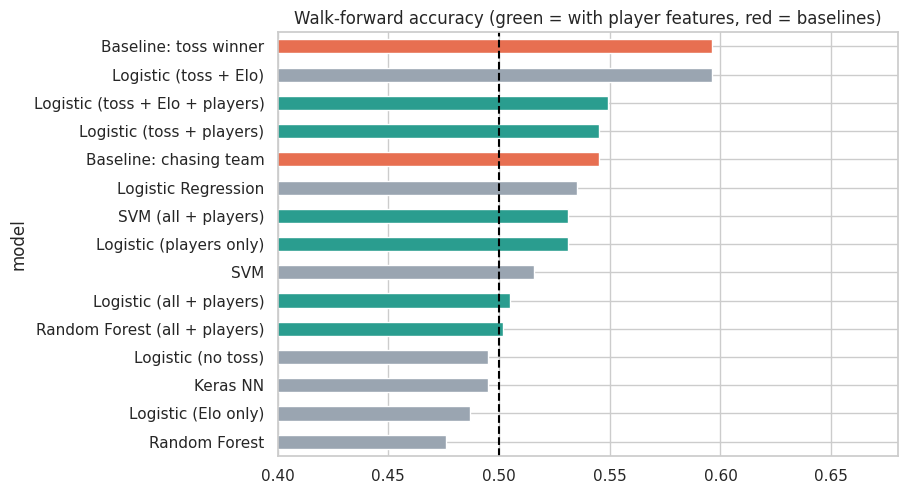

In [19]:
ref_chase = preds["Baseline: chasing team"] == y_pl
ref_toss  = preds["Baseline: toss winner"]  == y_pl
print(f"Baselines: chasing team {ref_chase.mean():.3f} | toss winner {ref_toss.mean():.3f}\n")
for n in pl_models:
    c = pl_preds[n] == y_pl
    lo, hi = acc_interval(c)
    print(f"{n:34s} acc={c.mean():.3f}  95% range [{lo:.3f}, {hi:.3f}]   p vs chasing = {mcnemar_p(c, ref_chase):.3f}   p vs toss rule = {mcnemar_p(c, ref_toss):.3f}")

show = results_all.loc[[i for i in results_all.index if not i.startswith("Baseline")] + ["Baseline: chasing team", "Baseline: toss winner"], "accuracy"].sort_values()
colors = ["#e76f51" if i.startswith("Baseline") else ("#2a9d8f" if "players" in i else "#9aa5b1") for i in show.index]
show.plot.barh(figsize=(8, 5.5), color=colors, title="Walk-forward accuracy (green = with player features, red = baselines)")
plt.axvline(0.5, color="black", ls="--"); plt.xlim(0.4, 0.68); plt.show()

### 12.5 What do the player features do inside the model?
Logistic Regression coefficients: a bar to the right means "when team1's number is higher, team1 is more likely to win". Remember that for **bowling economy a lower number is better**, so a negative bar there is the *expected* direction.

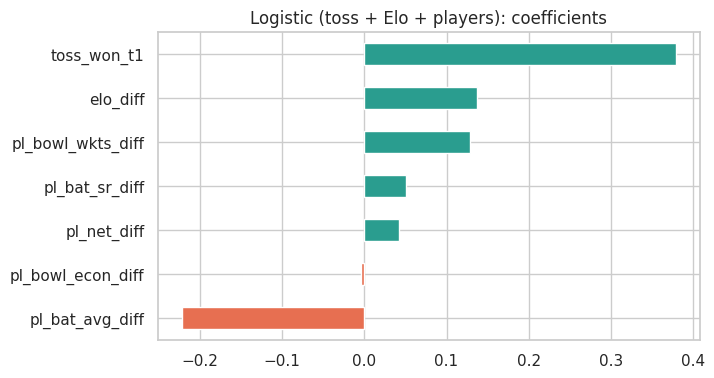

In [20]:
cols_all = ["toss_won_t1", "elo_diff"] + PLAYER_FEATURES
lr_pl = make_lr().fit(data[cols_all], data[TARGET])
coef_pl = pd.Series(lr_pl.named_steps["m"].coef_[0], index=cols_all).sort_values()
coef_pl.plot.barh(figsize=(7, 4), color=np.where(coef_pl > 0, "#2a9d8f", "#e76f51"),
                  title="Logistic (toss + Elo + players): coefficients"); plt.show()

### 12.6 Predict a match using the playing XI
`predict_match_players()` works like `predict_match()` but you also give the **11 players of each team** (as names). It uses the player model that scored the best AUC above. If you don't pass a squad, it uses each team's **most recent XI** from the data. As always it asks the model twice (each team as team1) and averages.

Player names must be written exactly as in the data (for example `"Babar Azam"`, `"Shaheen Shah Afridi"`). If a name is not found, the function tells you which one.

In [21]:
pl_best_name = results_pl["auc"].idxmax()
pl_make, pl_cols = pl_models[pl_best_name]
pl_best_model = pl_make().fit(data[pl_cols], data[TARGET])
print("Player model used for prediction:", pl_best_name)

def predict_match_players(team1, team2, venue, toss_winner, toss_decision, team1_xi=None, team2_xi=None, new_season=False):
    for t in (team1, team2):
        if t not in final_state.elo:
            raise ValueError(f"Unknown team '{t}'. Known teams: {sorted(final_state.elo)}")
    def to_ids(names, team):
        if names is None:
            return latest_xi[team]
        missing = [n for n in names if n not in name_to_id]
        if missing:
            raise ValueError(f"Player name(s) not found in the data: {missing}")
        return [name_to_id[n] for n in names]
    xi = {team1: to_ids(team1_xi, team1), team2: to_ids(team2_xi, team2)}
    st = copy.deepcopy(final_state)
    if new_season:
        st.new_season()

    def p_first_wins(a, b):
        bat_first = toss_winner if toss_decision == "bat" else (b if toss_winner == a else a)
        f = st.features(a, b, venue, toss_winner, toss_decision, bat_first)
        f.update(pstate.features(xi[a], xi[b]))
        return pl_best_model.predict_proba(pd.DataFrame([f])[pl_cols])[0, 1]

    p1 = (p_first_wins(team1, team2) + 1 - p_first_wins(team2, team1)) / 2
    print(f"{team1}: {p1:.0%}   vs   {team2}: {1 - p1:.0%}   -> predicted winner: {team1 if p1 >= 0.5 else team2}")
    return p1

_ = predict_match_players("Lahore Qalandars", "Multan Sultans", "Gaddafi Stadium, Lahore", "Lahore Qalandars", "field")
_ = predict_match_players("Karachi Kings", "Islamabad United", "National Stadium, Karachi", "Islamabad United", "bat")
print("\nThe most recent XI of Peshawar Zalmi in the data:", [id_to_name[p] for p in latest_xi["Peshawar Zalmi"]])

Player model used for prediction: Logistic (toss + players)
Lahore Qalandars: 59%   vs   Multan Sultans: 41%   -> predicted winner: Lahore Qalandars
Karachi Kings: 37%   vs   Islamabad United: 63%   -> predicted winner: Islamabad United

The most recent XI of Peshawar Zalmi in the data: ['Mohammad Haris', 'Babar Azam', 'BKG Mendis', 'AM Hardie', 'MG Bracewell', 'Abdul Samad', 'Farhan Yousaf', 'Iftikhar Ahmed', 'Sufiyan Muqeem', 'Mohammad Basit', 'Nahid Rana']


## Conclusion

**What we found (walk-forward test on 275 matches, 2018/19 to 2026):**
- **No complicated model beat the simple baselines.** Logistic Regression with all features, Random Forest, SVM and the Keras network all scored about 48-54% accuracy with AUC around 0.5. That is the same as guessing. None was significantly better than "pick the chasing team" (McNemar p-values above 0.05). The Keras network changes a little every run, so your exact Keras number may differ by a few points.
- **The toss is the only clear signal.** Picking the **toss winner** is right **59.6%** of the time, and the 2-feature model (toss + Elo) gets the same. Over all 354 matches the toss winner wins 58.8% (p = 0.001), which is unlikely to be luck. On the 275 walk-forward matches it is not *statistically* better than "pick the chasing team" (p = 0.125) because the sample is small. Honest wording: *"the toss looks like it matters a little; we cannot prove it beats the chasing rule"*.
- **Player-level features (Step 12) did not improve accuracy.** The best player model reached about 55% accuracy (AUC about 0.57), below the toss rule (59.6%). Adding the player features to *all* the other features made things worse (about 50-53%), because more noisy numbers on 354 matches lets a model memorise noise.
  - The code is working: the ratings show sensible players on top (Babar Azam, Fakhar Zaman and Mohammad Rizwan for batting, Rashid Khan for bowling economy).
  - The signal is simply weak. On their own, the player numbers separate winners from losers only slightly better than a coin flip (AUC about 0.46-0.54, similar to Elo).
  - Likely reasons: only 354 matches, so most players have few PSL matches to learn from; overseas players come and go every season; averaging 11 players hides the effect of one or two stars; and T20 cricket is very random.
- **Your first-notebook numbers were slightly optimistic.** Part of the 55-60% came from a non-random team1/team2 order, the `t1_home` bug and a small 76-match test set.

**Why this is still a good result:** an honest "we tested properly, including player-level features, and found PSL matches are very hard to predict" is more valuable than a high accuracy that came from leakage. Say it that way in your report.

**What could still improve it (future work):**
1. **Rate players with more data.** Cricsheet uses the same player ids in every league, so you can download IPL, Big Bash, etc. and build each player's ratings from thousands of matches instead of only PSL ones. This is the most promising next step, because the weak point here is too little history per player.
2. Pitch, weather and dew information.
3. Specific matchups (a batter against a bowler type, a bowler at a venue).
4. Re-run this notebook after each season to keep Elo, form and player ratings up to date.

**Limitations:** small data (354 matches), the "best" model was chosen on the same test seasons (slightly optimistic), and the playing XI and toss are known only at toss time, so this is a **prediction made at the toss**, not days before.